# PINN Eigen-solver for a 2D Finite Square Well with Central Walls (PyTorch)

2D extension of finite square well 1D eigenvalue problem (Jin, Mattheakis & Protopapas, arXiv:2203.00451).

$$-\frac12\nabla^2\psi(x,y)+V(x,y)\psi(x,y)=E\psi(x,y),\qquad V(x,y)=V_1(x)+V_1(y)$$

$$V_1(s)=\begin{cases}0,&0.05<|s|\leq1.7\\20,&\text{otherwise}\end{cases}$$

The potential is separable: $E_{ij}=e_i+e_j$ and $\psi_{ij}(x,y)=\phi_i(x)\phi_j(y)$.
Each eigenfunction has parity $(p_x,p_y)\in\{\pm1\}^2$. The four lowest states belong to four distinct parity classes.

The PINN uses embedded boundary conditions and parity, a normalized differential-equation residual,
normalization and orthogonality penalties, and a patience-based parity-class queue.


In [1]:
import copy
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from scipy.linalg import eigh_tridiagonal

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook")
print(f"Using device: {device}")

Using device: mps


In [2]:
# Problem (same 1D profile in x and y)
half_width = 1.7
wall_half_width = 0.05
V0 = 20.0
xL, xR = -6.0, 6.0

# Collocation sampling
n_uniform = 2000
n_box = 4000
box_half = 2.5
n_band = 1000
band_half = 0.25

# Network / optimizer
hidden = 64
omega = 6.0
lr = 8e-3
lr_decay_every, lr_min = 3000, 1e-4

# Loss weights
nu_norm, nu_orth = 1.0, 1.0

# Solution recognition
parity_classes = [(+1, +1), (+1, -1), (-1, +1), (-1, -1)]
n_states = len(parity_classes)
window = 1000
patience_tol = 1e-2
de_tol = 5e-2
jump_band = 0.05
norm_tol = 5e-3
min_epochs = 6000
max_epochs = 60000

In [3]:
class Sin(nn.Module):
    def forward(self, x):
        return torch.sin(x)

def g_boundary(s):
    return (1 - torch.exp(-(s - xL))) * (1 - torch.exp(s - xR))

class EigenNet2D(nn.Module):
    """psi(x,y) = g(x) g(y) N(x,y,E) with embedded parity (px,py)."""
    def __init__(self, hidden=64, parity=(1, 1)):
        super().__init__()
        self.parity = parity
        self.E_in = nn.Linear(1, 1)
        self.hidden = nn.Sequential(nn.Linear(3, hidden), Sin(),
                                    nn.Linear(hidden, hidden), Sin())
        self.out = nn.Linear(hidden, 1)

    def energy(self):
        return self.E_in(torch.ones(1, 1, device=self.E_in.weight.device)).squeeze()

    def forward(self, xy):
        x, y = xy[:, :1], xy[:, 1:2]
        E = self.E_in(torch.ones_like(x))
        px, py = self.parity
        feats = 0
        for sx, sy, w in ((1, 1, 1), (1, -1, py),
                          (-1, 1, px), (-1, -1, px * py)):
            inp = torch.cat((omega * sx * x, omega * sy * y, E), dim=1)
            feats = feats + w * self.hidden(inp)
        return g_boundary(x) * g_boundary(y) * self.out(feats)

def potential_1d_np(s):
    a = np.abs(s)
    return np.where((a > wall_half_width) & (a < half_width), 0.0, V0)

def potential_1d(s):
    a = torch.abs(s)
    inside = (a > wall_half_width) & (a < half_width)
    return torch.where(inside, torch.zeros_like(s), V0 * torch.ones_like(s))

def potential(xy):
    return potential_1d(xy[:, :1]) + potential_1d(xy[:, 1:2])

box_area = (2 * box_half) ** 2
box_slice = slice(n_uniform, n_uniform + n_box)
jumps = torch.tensor([-half_width, -wall_half_width, wall_half_width, half_width],
                     device=device)

def away_from_jumps(xy):
    dist = torch.abs(xy.unsqueeze(-1) - jumps).min(dim=-1).values
    return (dist > jump_band).all(dim=1)

def sample_points():
    uniform = xL + (xR - xL) * torch.rand(n_uniform, 2, device=device)
    box = box_half * (2 * torch.rand(n_box, 2, device=device) - 1)
    band = 2 * torch.rand(n_band, 2, device=device) - 1
    band_x = torch.stack((band_half * band[:, 0], box_half * band[:, 1]), 1)
    band_y = band_x.flip(1)
    return torch.cat((uniform, box, band_x, band_y)).requires_grad_(True)

def compute_losses(model, xy, stored):
    psi = model(xy)
    E = model.energy()
    grad = torch.autograd.grad(psi, xy, torch.ones_like(psi), create_graph=True)[0]
    psi_xx = torch.autograd.grad(grad[:, :1], xy,
                                torch.ones_like(grad[:, :1]), create_graph=True)[0][:, :1]
    psi_yy = torch.autograd.grad(grad[:, 1:2], xy,
                                torch.ones_like(grad[:, 1:2]), create_graph=True)[0][:, 1:2]
    res2 = (-0.5 * (psi_xx + psi_yy) + potential(xy) * psi - E * psi) ** 2
    psi_box = psi[box_slice]
    box_norm2 = torch.mean(psi_box ** 2) * box_area
    L_de = torch.mean(res2) / box_norm2
    # Exclude discontinuity lines when judging convergence.
    L_de_smooth = torch.mean(res2.detach()[away_from_jumps(xy.detach())])
    L_norm = (torch.sqrt(box_norm2) - 1.0) ** 2
    if stored:
        with torch.no_grad():
            xy_box = xy[box_slice].detach()
            psi_eigen = sum(m(xy_box) for m in stored)
        L_orth = torch.mean(psi_eigen * psi_box) ** 2 / (
            torch.mean(psi_eigen ** 2) * torch.mean(psi_box ** 2))
    else:
        L_orth = torch.zeros((), device=xy.device)
    return L_de, L_norm, L_orth, L_de_smooth

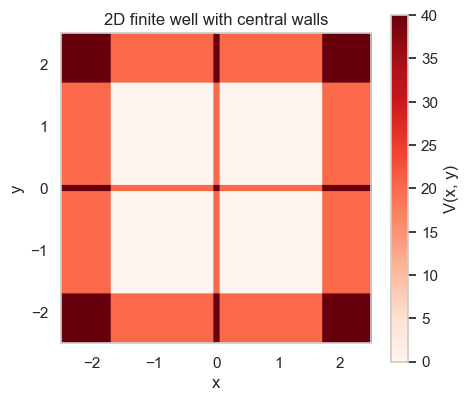

In [4]:
s_plot = np.linspace(-box_half, box_half, 400)
X_plot, Y_plot = np.meshgrid(s_plot, s_plot)
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(potential_1d_np(X_plot) + potential_1d_np(Y_plot),
               origin="lower", cmap="Reds",
               extent=[-box_half, box_half, -box_half, box_half])
fig.colorbar(im, ax=ax, label="V(x, y)")
ax.set(xlabel="x", ylabel="y", title="2D finite well with central walls")
ax.grid(False)
plt.show()

## Training (Algorithm 1)

Search the parity classes in order. When a state is accepted, freeze a copy and advance
to the next parity class. If patience is reached without meeting the differential-equation
and normalization thresholds, move the class to the back of the queue and retry later.

**Convergence detail:** The differential residual is evaluated away from potential
discontinuities when deciding whether to accept a state. The training residual is
divided by the wavefunction norm to prevent artificial improvement by shrinking the output.


In [5]:
def new_model(parity):
    m = EigenNet2D(hidden, parity).to(device)
    return m, torch.optim.Adam(m.parameters(), lr=lr)

def set_lr(opt, epochs_in_state):
    for group in opt.param_groups:
        group["lr"] = max(lr * 0.5 ** (epochs_in_state // lr_decay_every), lr_min)

pending = list(parity_classes)
model, optimizer = new_model(pending[0])
stored_models, found, events, history = [], [], [], []
last_event = 0
t_start = time.time()

for epoch in range(max_epochs):
    xy = sample_points()
    L_de, L_norm, L_orth, L_de_smooth = compute_losses(model, xy, stored_models)
    loss = L_de + nu_norm * L_norm + nu_orth * L_orth
    set_lr(optimizer, epoch - last_event)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    E = model.energy().item()
    history.append({"epoch": epoch, "E": E, "L_DE": L_de.item(),
                    "L_DE_smooth": L_de_smooth.item(), "L_norm": L_norm.item(),
                    "L_orth": L_orth.item(), "parity": str(model.parity)})
    if epoch % 500 == 0:
        print(f"Epoch {epoch:6d} | parity {model.parity} | E {E:.4f} | "
              f"L_DE {L_de.item():.2e} | L_DE_smooth {L_de_smooth.item():.2e} | "
              f"L_norm {L_norm.item():.2e} | L_orth {L_orth.item():.2e} | "
              f"{time.time() - t_start:.0f}s")

    if epoch - last_event < max(min_epochs, 2 * window):
        continue
    de_recent = [h["L_DE_smooth"] for h in history[-2 * window:]]
    prev, cur = np.mean(de_recent[:window]), np.mean(de_recent[window:])
    if (prev - cur) / prev >= patience_tol:
        continue

    if cur < de_tol and L_norm.item() < norm_tol:
        frozen = copy.deepcopy(model).eval().requires_grad_(False)
        stored_models.append(frozen)
        found.append((E, model.parity))
        events.append({"epoch": epoch, "event": "stored", "E": E})
        print(f" >> stored eigenstate E = {E:.4f} (parity {model.parity}) at epoch {epoch}")
        pending.pop(0)
        if not pending:
            break
    else:
        events.append({"epoch": epoch, "event": "switch", "E": E})
        print(f" >> false solution E = {E:.4f} (L_DE_smooth {cur:.2e}, "
              f"L_norm {L_norm.item():.1e}); moving parity to the back of the queue")
        pending.append(pending.pop(0))
    model, optimizer = new_model(pending[0])
    last_event = epoch

print(f"Found {len(found)} states in {time.time() - t_start:.0f}s: "
      f"{[(round(e, 4), p) for e, p in found]}")

Epoch      0 | parity (1, 1) | E 0.5450 | L_DE 2.03e+01 | L_DE_smooth 1.45e+01 | L_norm 2.19e-02 | L_orth 0.00e+00 | 5s
Epoch    500 | parity (1, 1) | E 0.9478 | L_DE 1.76e-01 | L_DE_smooth 1.02e-01 | L_norm 1.84e-04 | L_orth 0.00e+00 | 34s
Epoch   1000 | parity (1, 1) | E 1.4170 | L_DE 1.44e-01 | L_DE_smooth 6.21e-02 | L_norm 4.71e-04 | L_orth 0.00e+00 | 56s
Epoch   1500 | parity (1, 1) | E 1.6661 | L_DE 1.16e-01 | L_DE_smooth 4.17e-02 | L_norm 3.50e-04 | L_orth 0.00e+00 | 78s
Epoch   2000 | parity (1, 1) | E 1.6403 | L_DE 1.33e-01 | L_DE_smooth 7.82e-02 | L_norm 5.48e-04 | L_orth 0.00e+00 | 98s
Epoch   2500 | parity (1, 1) | E 1.8270 | L_DE 1.21e-01 | L_DE_smooth 5.93e-02 | L_norm 6.02e-04 | L_orth 0.00e+00 | 119s
Epoch   3000 | parity (1, 1) | E 1.8714 | L_DE 1.15e-01 | L_DE_smooth 4.24e-02 | L_norm 2.71e-05 | L_orth 0.00e+00 | 139s
Epoch   3500 | parity (1, 1) | E 1.8862 | L_DE 9.44e-02 | L_DE_smooth 3.47e-02 | L_norm 9.94e-06 | L_orth 0.00e+00 | 159s
Epoch   4000 | parity (1, 1) |

## Reference solution

Solve the 1D problem by finite differences, then construct separable 2D states:
$E_{ij}=e_i+e_j$, $\psi_{ij}(x,y)=\phi_i(x)\phi_j(y)$.
The parity of $\phi_i$ is $(-1)^i$.


In [6]:
n_fd = 4000
n_1d = 6
x_fd = np.linspace(xL, xR, n_fd + 2)[1:-1]
h_fd = x_fd[1] - x_fd[0]
e_1d, phi_fd = eigh_tridiagonal(
    1.0 / h_fd**2 + potential_1d_np(x_fd),
    -0.5 / h_fd**2 * np.ones(n_fd - 1),
    select="i", select_range=(0, n_1d - 1)
)

s_np = np.linspace(-box_half, box_half, 201)
phi_1d = np.stack([np.interp(s_np, x_fd, phi_fd[:, i]) for i in range(n_1d)])
ref_states = sorted(
    ({"E": e_1d[i] + e_1d[j], "ij": (i, j),
      "parity": ((-1)**i, (-1)**j)}
     for i in range(n_1d) for j in range(n_1d)),
    key=lambda s: s["E"]
)
X_np, Y_np = np.meshgrid(s_np, s_np, indexing="ij")

def normalize_2d(psi):
    return psi / np.sqrt(np.trapezoid(np.trapezoid(psi**2, s_np, axis=1), s_np))

def ref_wavefunction(i, j):
    return normalize_2d(np.outer(phi_1d[i], phi_1d[j]))

print("1D energies:", np.round(e_1d, 4))
print("Lowest 2D states:", [(round(s["E"], 4), s["ij"]) for s in ref_states[:n_states]])

1D energies: [ 0.9599  1.428   4.1315  5.6712  9.8052 12.5471]
Lowest 2D states: [(np.float64(1.9197), (0, 0)), (np.float64(2.3879), (0, 1)), (np.float64(2.3879), (1, 0)), (np.float64(2.856), (1, 1))]


In [7]:
xy_t = torch.tensor(np.stack([X_np.ravel(), Y_np.ravel()], 1),
                    dtype=torch.float32, device=device)
rows, psi_pinn, psi_ref = [], [], []
for idx in np.argsort([E for E, _ in found]):
    E_p, parity = found[idx]
    ref = min((s for s in ref_states if s["parity"] == parity),
              key=lambda s: abs(s["E"] - E_p))
    with torch.no_grad():
        psi = stored_models[idx](xy_t).cpu().numpy().reshape(X_np.shape)
    psi = normalize_2d(psi)
    psi_r = ref_wavefunction(*ref["ij"])
    if np.sum(psi * psi_r) < 0:
        psi = -psi
    psi_pinn.append(psi)
    psi_ref.append(psi_r)
    rows.append({"ij": ref["ij"], "parity": parity, "E_PINN": E_p,
                 "E_ref": ref["E"],
                 "E rel. err (%)": 100 * abs(E_p - ref["E"]) / ref["E"],
                 "MSE / max|psi_ref|": np.mean((psi - psi_r)**2) /
                                      np.max(np.abs(psi_r))})
df_results = pd.DataFrame(rows)
df_results

,ij,parity,E_PINN,E_ref,E rel. err (%),MSE / max|psi_ref|
0,"(0, 0)","(1, 1)",1.861453,1.919710,3.034715,0.004864
1,"(0, 1)","(1, -1)",2.361265,2.387877,1.114457,0.002126
2,"(1, 0)","(-1, 1)",2.365968,2.387877,0.917502,0.002366
3,"(1, 1)","(-1, -1)",2.849422,2.856043,0.231819,0.000042


In [8]:
overlap = np.array([
    [np.trapezoid(np.trapezoid(a * b, s_np, axis=1), s_np)
     for b in psi_pinn] for a in psi_pinn
])
labels = [str(ij) for ij in df_results["ij"]]
pd.DataFrame(overlap, index=labels, columns=labels).round(4)

,"(0, 0)","(0, 1)","(1, 0)","(1, 1)"
"(0, 0)",1.0000,-0.0006,0.001,-0.0006
"(0, 1)",-0.0006,1.0000,-0.000,0.0000
"(1, 0)",0.0010,-0.0000,1.000,-0.0000
"(1, 1)",-0.0006,0.0000,-0.000,1.0000


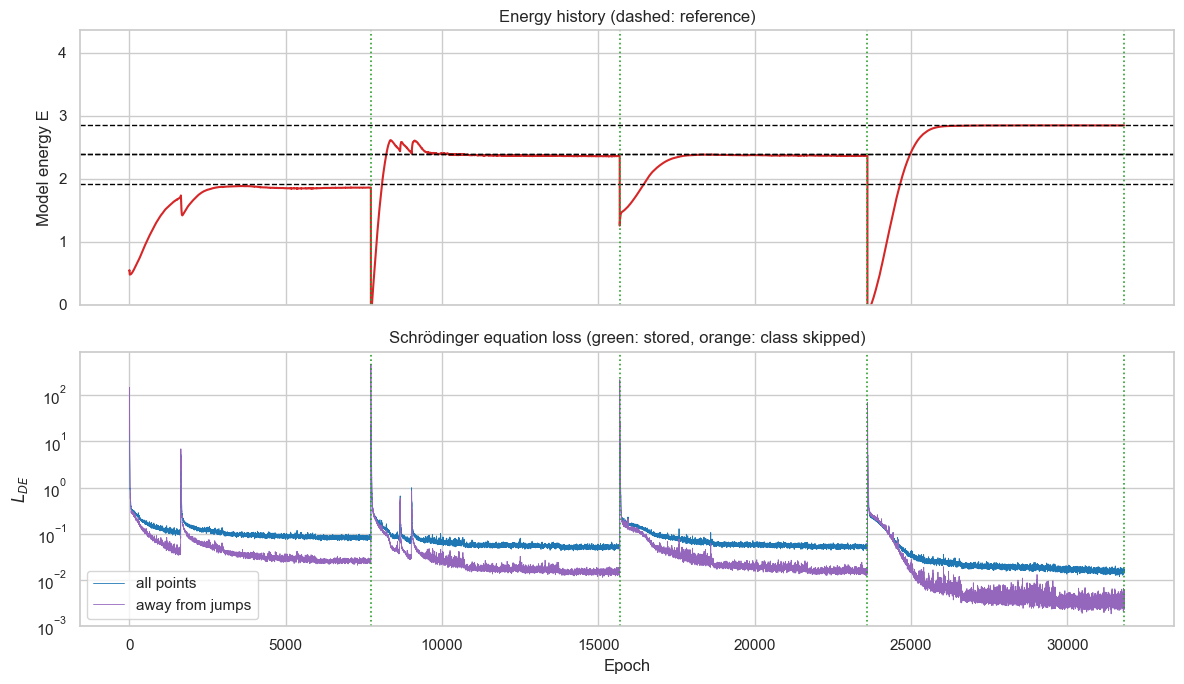

In [9]:
df_hist = pd.DataFrame(history)
df_events = pd.DataFrame(events)
E_ref_lowest = [s["E"] for s in ref_states[:n_states]]

fig, (ax_E, ax_L) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sns.lineplot(data=df_hist, x="epoch", y="E", color="tab:red", ax=ax_E)
for E_k in E_ref_lowest:
    ax_E.axhline(E_k, color="black", linestyle="--", linewidth=1)
ax_E.set(ylim=(0, max(E_ref_lowest) + 1.5), ylabel="Model energy E",
         title="Energy history (dashed: reference)")

sns.lineplot(data=df_hist, x="epoch", y="L_DE", color="tab:blue",
             linewidth=0.6, ax=ax_L, label="all points")
sns.lineplot(data=df_hist, x="epoch", y="L_DE_smooth", color="tab:purple",
             linewidth=0.6, ax=ax_L, label="away from jumps")
for _, ev in df_events.iterrows():
    color = "tab:green" if ev["event"] == "stored" else "tab:orange"
    for a in (ax_E, ax_L):
        a.axvline(ev["epoch"], color=color, linestyle=":", linewidth=1.2)
ax_L.set(yscale="log", xlabel="Epoch", ylabel=r"$L_{DE}$",
         title="Schrödinger equation loss (green: stored, orange: class skipped)")
plt.tight_layout()
plt.show()

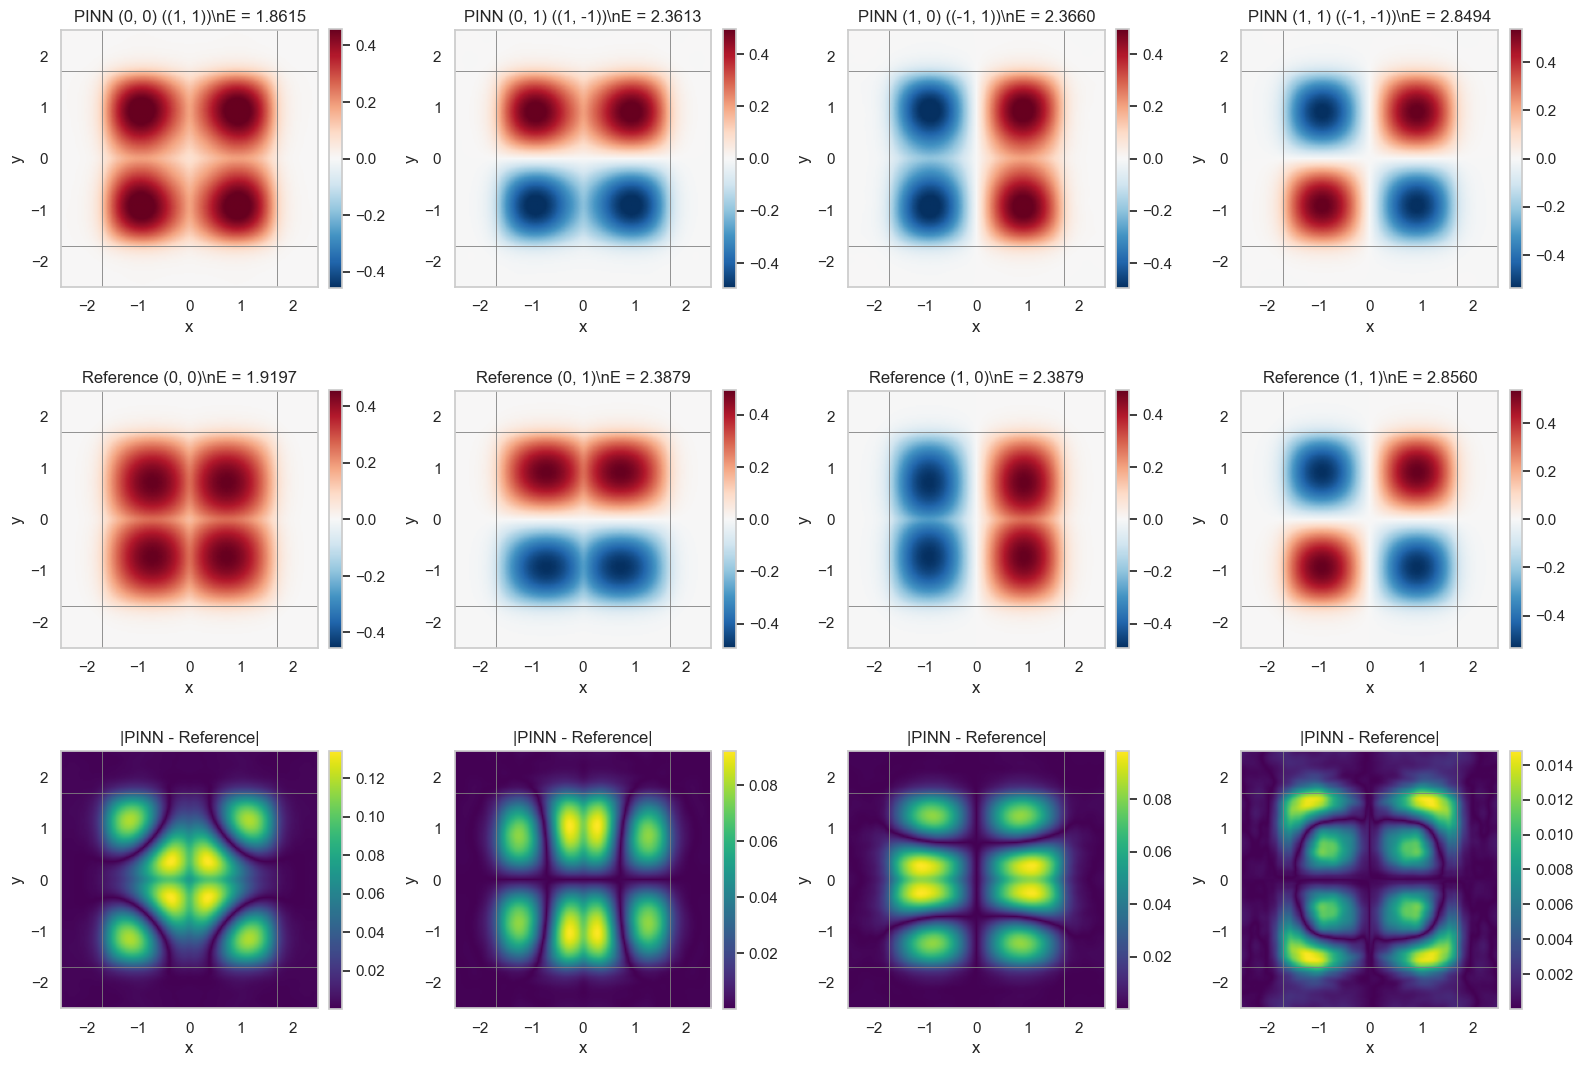

In [10]:
n_found = len(psi_pinn)
if n_found:
    fig, axes = plt.subplots(3, n_found, figsize=(4 * n_found, 11),
                             squeeze=False)
    extent = [-box_half, box_half, -box_half, box_half]
    for col, row in df_results.iterrows():
        vmax = np.max(np.abs(psi_ref[col]))
        panels = [
            (psi_pinn[col], f"PINN {row['ij']} ({row['parity']})\\nE = {row['E_PINN']:.4f}",
             "RdBu_r", -vmax, vmax),
            (psi_ref[col], f"Reference {row['ij']}\\nE = {row['E_ref']:.4f}",
             "RdBu_r", -vmax, vmax),
            (np.abs(psi_pinn[col] - psi_ref[col]), "|PINN - Reference|",
             "viridis", None, None)
        ]
        for r, (data, title, cmap, vmin, vmax_) in enumerate(panels):
            ax = axes[r, col]
            im = ax.imshow(data.T, origin="lower", extent=extent,
                           cmap=cmap, vmin=vmin, vmax=vmax_, aspect="equal")
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            for w in (-half_width, half_width):
                ax.axhline(w, color="gray", linewidth=0.6)
                ax.axvline(w, color="gray", linewidth=0.6)
            ax.set(title=title, xlabel="x", ylabel="y")
            ax.grid(False)
    plt.tight_layout()
    plt.show()
    fig.savefig("finite_square_well_2d_central_walls_PINN_results.png", bbox_inches="tight")
else:
    print("No states found; nothing to plot.")